Logistic regression keeps linear regression's core exactly &mdash; a weighted sum
$z = \mathbf{x}^\top\mathbf{w}$ &mdash; and changes only what happens next.

Why change anything? Because a linear model outputs any real number, and a probability
must lie in $[0,1]$. Fitting squared error to 0/1 labels gives predictions above 1 and
below 0, and the loss is not even convex once squashed. Both problems are solved by the
same substitution:

$$p = \sigma(z) = \frac{1}{1 + e^{-z}}
\qquad\qquad
\mathcal{L} = -\sum_i \big[\, y_i \log p_i + (1-y_i)\log(1-p_i) \,\big]$$

That pairing &mdash; sigmoid **and** log-loss &mdash; is not arbitrary. It produces a gradient of
startling simplicity:

$$\nabla \mathcal{L} = X^\top(\mathbf{p} - \mathbf{y})$$

which is the *same shape* as the least-squares gradient, with predicted probabilities in
place of predicted values. Everything below derives that, computes it by hand, runs both
gradient descent and Newton's method, and checks the result against scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


---
# 1. The Data

20 EEG epochs, two features, two classes. The same table is reused by the KNN, SVM and
Naive Bayes walkthroughs so the decision boundaries can be compared directly.

Two epochs sit deliberately in the wrong region, so **no straight line separates the
classes perfectly**. That matters: perfectly separable data makes logistic regression's
weights diverge to infinity.

In [2]:
# ----------------------------------------------------------------------------
#  20 EEG epochs, two features, two classes. Small enough to print in full,
#  and deliberately NOT perfectly separable.
# ----------------------------------------------------------------------------
feat2 = ["spike_rate", "line_length"]

P = np.array([
    [1.0, 12.0], [1.6, 15.0], [0.7, 11.0], [2.1, 18.0], [1.3, 14.0],
    [2.6, 21.0], [0.9, 16.0], [1.9, 13.0], [3.1, 24.0], [2.3, 17.0],
    [6.2, 41.0], [7.1, 47.0], [5.4, 38.0], [8.0, 52.0], [6.7, 44.0],
    [5.9, 49.0], [7.6, 39.0], [6.0, 35.0], [4.7, 43.0], [8.3, 46.0],
])
t2 = np.array([0]*10 + [1]*10)

# two deliberate overlaps, so no straight line separates the data perfectly
P[9]  = [4.4, 33.0]      # a class-0 epoch pushed into class-1 territory
t2[9] = 0
P[18] = [3.6, 27.0]      # a class-1 epoch pushed down toward class 0
t2[18] = 1

n2 = len(P)
ep_ids = [f"ep{i:02d}" for i in range(n2)]
cls_names = ["no seizure", "seizure"]

print(f"{n2} epochs x {P.shape[1]} features, classes {np.bincount(t2).tolist()}\n")
hdr = f"{'id':>6}  {feat2[0]:>11}  {feat2[1]:>12}  {'class':>6}  {'label':>12}"
print(hdr); print("-" * len(hdr))
for i in range(n2):
    print(f"{ep_ids[i]:>6}  {P[i,0]:>11.1f}  {P[i,1]:>12.1f}  {t2[i]:>6}  "
          f"{cls_names[t2[i]]:>12}")
print("-" * len(hdr))
print(f"\nfeature means : {np.round(P.mean(axis=0), 3)}")
print(f"feature stds  : {np.round(P.std(axis=0), 3)}")
print(f"\nNote the scales: {feat2[1]} spans ~{P[:,1].ptp() if hasattr(P[:,1],'ptp') else np.ptp(P[:,1]):.0f} "
      f"while {feat2[0]} spans ~{np.ptp(P[:,0]):.0f}.")
print("Any algorithm that measures DISTANCE will be dominated by the larger one")
print("unless the features are scaled - that matters for KNN and SVM below.")

20 epochs x 2 features, classes [10, 10]

    id   spike_rate   line_length   class         label
-------------------------------------------------------
  ep00          1.0          12.0       0    no seizure
  ep01          1.6          15.0       0    no seizure
  ep02          0.7          11.0       0    no seizure
  ep03          2.1          18.0       0    no seizure
  ep04          1.3          14.0       0    no seizure
  ep05          2.6          21.0       0    no seizure
  ep06          0.9          16.0       0    no seizure
  ep07          1.9          13.0       0    no seizure
  ep08          3.1          24.0       0    no seizure
  ep09          4.4          33.0       0    no seizure
  ep10          6.2          41.0       1       seizure
  ep11          7.1          47.0       1       seizure
  ep12          5.4          38.0       1       seizure
  ep13          8.0          52.0       1       seizure
  ep14          6.7          44.0       1       seizure
  ep15

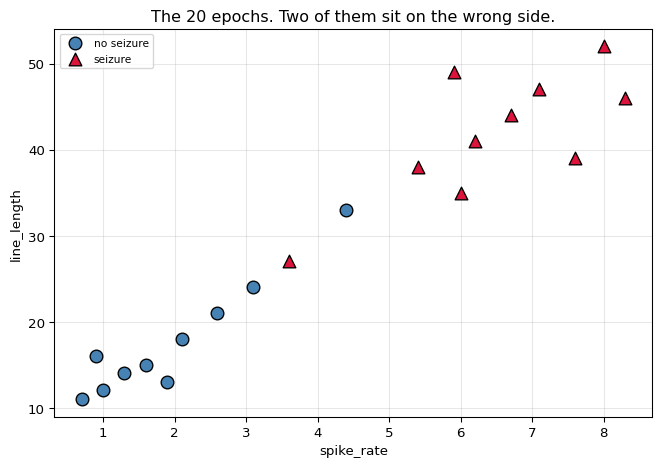

   ep09: spike_rate=4.4, line_length=33.0, class 0 (no seizure)  <- the awkward one
   ep18: spike_rate=3.6, line_length=27.0, class 1 (seizure)  <- the awkward one


In [3]:
def plot2d(ax=None, scaled=False, title="", legend=True):
    A = Pz if scaled else P
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(7, 5))
    for c, (col, mk) in enumerate([("steelblue", "o"), ("crimson", "^")]):
        m = t2 == c
        ax.scatter(A[m, 0], A[m, 1], c=col, marker=mk, s=90, edgecolor="k",
                   label=cls_names[c], zorder=3)
    ax.set(xlabel=feat2[0] + (" (scaled)" if scaled else ""),
           ylabel=feat2[1] + (" (scaled)" if scaled else ""), title=title)
    if legend:
        ax.legend(fontsize=8)
    ax.grid(alpha=.3)
    return ax

Pz = (P - P.mean(axis=0)) / P.std(axis=0)     # standardised copy, used later
plot2d(title="The 20 epochs. Two of them sit on the wrong side.")
plt.tight_layout(); plt.show()

for i in (9, 18):
    print(f"   {ep_ids[i]}: {feat2[0]}={P[i,0]}, {feat2[1]}={P[i,1]}, "
          f"class {t2[i]} ({cls_names[t2[i]]})  <- the awkward one")

---
# 2. The Sigmoid and the Log-Odds

$$\sigma(z) = \frac{1}{1+e^{-z}}, \qquad \sigma'(z) = \sigma(z)\,(1-\sigma(z))$$

The inverse is the **logit**, and it is what the model is actually linear in:

$$z = \log\frac{p}{1-p} = \mathbf{x}^\top\mathbf{w}$$

So logistic regression asserts that the **log-odds** are a linear function of the
features. A one-unit increase in $x_j$ multiplies the odds by $e^{w_j}$, whatever the
starting point &mdash; which is why coefficients are usually reported as odds ratios.

      z    sigma(z)     odds e^z   derivative
----------------------------------------------
   -6.0    0.002473       0.0025     0.002467
   -3.0    0.047426       0.0498     0.045177
   -2.0    0.119203       0.1353     0.104994
   -1.0    0.268941       0.3679     0.196612
   -0.5    0.377541       0.6065     0.235004
    0.0    0.500000       1.0000     0.250000
    0.5    0.622459       1.6487     0.235004
    1.0    0.731059       2.7183     0.196612
    2.0    0.880797       7.3891     0.104994
    3.0    0.952574      20.0855     0.045177
    6.0    0.997527     403.4288     0.002467
----------------------------------------------

sigma(0) = 0.500000   (odds 1:1, the decision boundary)
the derivative peaks at z = 0 with value 0.25 and vanishes at both ends -
that vanishing is why a very confident wrong prediction produces almost no
gradient, and why the Hessian below shrinks for confident points.



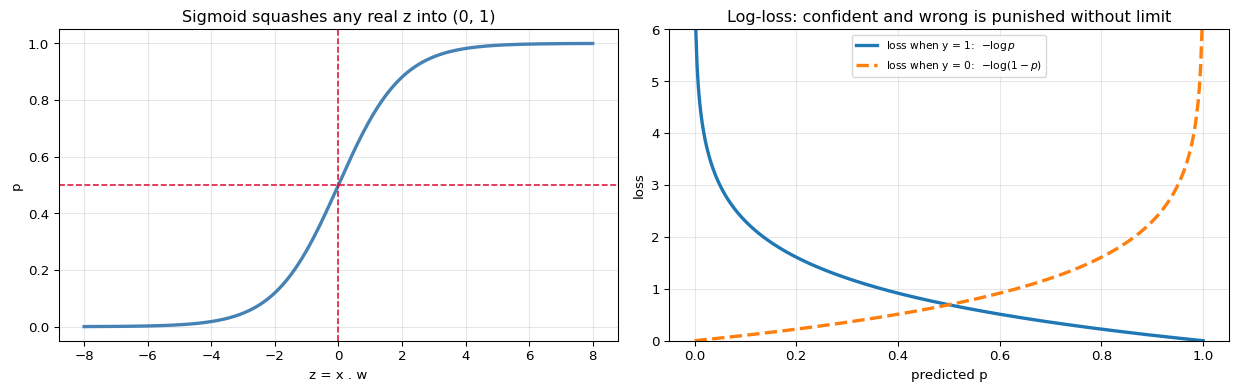

Right panel: as p -> 0 while y = 1, the loss goes to infinity. Squared error
would top out at 1. That unbounded penalty is what stops the model from
being confidently wrong.


In [4]:
def sigmoid(z):
    return np.where(z >= 0, 1/(1+np.exp(-np.abs(z))), np.exp(-np.abs(z))/(1+np.exp(-np.abs(z))))

zz = np.array([-6, -3, -2, -1, -0.5, 0, 0.5, 1, 2, 3, 6], dtype=float)
print(f"{'z':>7}  {'sigma(z)':>10}  {'odds e^z':>11}  {'derivative':>11}")
print("-" * 46)
for z in zz:
    s = float(sigmoid(z))
    print(f"{z:>7.1f}  {s:>10.6f}  {np.exp(z):>11.4f}  {s*(1-s):>11.6f}")
print("-" * 46)

print(f"\nsigma(0) = {float(sigmoid(0)):.6f}   (odds 1:1, the decision boundary)")
print(f"the derivative peaks at z = 0 with value 0.25 and vanishes at both ends -")
print(f"that vanishing is why a very confident wrong prediction produces almost no")
print(f"gradient, and why the Hessian below shrinks for confident points.\n")

gz = np.linspace(-8, 8, 400)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(gz, sigmoid(gz), lw=2.5, color="steelblue")
axes[0].axhline(.5, color="crimson", ls="--", lw=1.2)
axes[0].axvline(0, color="crimson", ls="--", lw=1.2)
axes[0].set(xlabel="z = x . w", ylabel="p", title="Sigmoid squashes any real z into (0, 1)")
axes[0].grid(alpha=.3)

p_ = np.linspace(1e-4, 1-1e-4, 400)
axes[1].plot(p_, -np.log(p_), lw=2.5, label="loss when y = 1:  $-\\log p$")
axes[1].plot(p_, -np.log(1-p_), lw=2.5, ls="--", label="loss when y = 0:  $-\\log(1-p)$")
axes[1].set(xlabel="predicted p", ylabel="loss", ylim=(0, 6),
            title="Log-loss: confident and wrong is punished without limit")
axes[1].legend(fontsize=8); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Right panel: as p -> 0 while y = 1, the loss goes to infinity. Squared error")
print("would top out at 1. That unbounded penalty is what stops the model from")
print("being confidently wrong.")

---
# 3. Where the Gradient Comes From

This is the derivation worth doing once by hand. For a single sample, with
$z = \mathbf{x}^\top\mathbf{w}$ and $p = \sigma(z)$:

$$\ell = -\big[y\log p + (1-y)\log(1-p)\big]$$

$$\frac{\partial \ell}{\partial p} = -\frac{y}{p} + \frac{1-y}{1-p} = \frac{p-y}{p(1-p)}
\qquad\qquad
\frac{\partial p}{\partial z} = p(1-p)$$

Multiply, and the awkward $p(1-p)$ **cancels exactly**:

$$\frac{\partial \ell}{\partial z} = \frac{p-y}{p(1-p)} \cdot p(1-p) = p - y$$

$$\boxed{\;\frac{\partial \ell}{\partial \mathbf{w}} = (p - y)\,\mathbf{x}
\qquad\Longrightarrow\qquad
\nabla\mathcal{L} = X^\top(\mathbf{p} - \mathbf{y})\;}$$

That cancellation is the whole reason log-loss is paired with the sigmoid. With squared
error the $p(1-p)$ factor survives and multiplies the gradient by nearly zero whenever
the model is confident &mdash; so a confidently *wrong* prediction would barely learn.

In [5]:
Xd = np.column_stack([np.ones(n2), Pz])       # bias + standardised features
cols = ["1 (bias)"] + feat2
yb = t2.astype(float)

w0 = np.zeros(3)
z0 = Xd @ w0
p0 = sigmoid(z0)

print("at w = 0, every prediction is p = 0.5 (maximum uncertainty)\n")
print(f"{'id':>6}  {'z':>8}  {'p':>8}  {'y':>4}  {'p - y':>9}")
print("-" * 40)
for i in range(n2):
    print(f"{ep_ids[i]:>6}  {z0[i]:>8.4f}  {p0[i]:>8.4f}  {int(yb[i]):>4}  {p0[i]-yb[i]:>9.4f}")
print("-" * 40)

grad0 = Xd.T @ (p0 - yb)
print(f"\ngradient = X^T (p - y):")
for c, gv in zip(cols, grad0):
    print(f"   {c:>12}: {gv:>10.6f}")

loss0 = -np.sum(yb*np.log(p0) + (1-yb)*np.log(1-p0))
print(f"\nloss at w = 0 : {loss0:.6f}")
print(f"   = -{n2} * log(0.5) = {-n2*np.log(0.5):.6f}   "
      f"MATCH: {np.isclose(loss0, -n2*np.log(0.5))}")
print(f"\nThat is the reference point every logistic model must beat: {n2} samples")
print(f"each contributing log(2) = {np.log(2):.4f} nats of surprise.")

print(f"\n\ncomparing the two loss choices on a confidently WRONG prediction")
print(f"(true y = 1, model says p = 0.01):\n")
pw = 0.01
print(f"   log-loss      : -log({pw}) = {-np.log(pw):.4f}")
print(f"   squared error : (1 - {pw})^2 = {(1-pw)**2:.4f}")
print(f"   d(log-loss)/dz      = p - y = {pw - 1:+.4f}")
print(f"   d(squared err)/dz   = 2(p-y)p(1-p) = {2*(pw-1)*pw*(1-pw):+.6f}")
print(f"\n   the squared-error gradient is {abs((pw-1)/(2*(pw-1)*pw*(1-pw))):.0f}x smaller -")
print(f"   it would barely correct this mistake.")

at w = 0, every prediction is p = 0.5 (maximum uncertainty)

    id         z         p     y      p - y
----------------------------------------
  ep00    0.0000    0.5000     0     0.5000
  ep01    0.0000    0.5000     0     0.5000
  ep02    0.0000    0.5000     0     0.5000
  ep03    0.0000    0.5000     0     0.5000
  ep04    0.0000    0.5000     0     0.5000
  ep05    0.0000    0.5000     0     0.5000
  ep06    0.0000    0.5000     0     0.5000
  ep07    0.0000    0.5000     0     0.5000
  ep08    0.0000    0.5000     0     0.5000
  ep09    0.0000    0.5000     0     0.5000
  ep10    0.0000    0.5000     1    -0.5000
  ep11    0.0000    0.5000     1    -0.5000
  ep12    0.0000    0.5000     1    -0.5000
  ep13    0.0000    0.5000     1    -0.5000
  ep14    0.0000    0.5000     1    -0.5000
  ep15    0.0000    0.5000     1    -0.5000
  ep16    0.0000    0.5000     1    -0.5000
  ep17    0.0000    0.5000     1    -0.5000
  ep18    0.0000    0.5000     1    -0.5000
  ep19    0.0000  

---
# 4. Fitting by Gradient Descent

The loss is convex in $\mathbf{w}$, so there is a single global minimum &mdash; but unlike
least squares there is **no closed form**, because setting $X^\top(\sigma(X\mathbf{w}) - \mathbf{y}) = 0$
gives an equation $\mathbf{w}$ cannot be factored out of. Iteration is the only option.

$$\mathbf{w} \leftarrow \mathbf{w} - \eta\, X^\top(\mathbf{p} - \mathbf{y})$$

In [6]:
def log_loss(w_, Xm=Xd, yv=yb):
    p_ = sigmoid(Xm @ w_)
    eps = 1e-12
    return -np.sum(yv*np.log(p_+eps) + (1-yv)*np.log(1-p_+eps))

def fit_gd(eta=0.05, iters=3000):
    w_ = np.zeros(Xd.shape[1])
    hist = []
    for k in range(iters):
        p_ = sigmoid(Xd @ w_)
        w_ = w_ - eta * (Xd.T @ (p_ - yb))
        hist.append(log_loss(w_))
    return w_, np.array(hist)

w_gd, hist_gd = fit_gd()

print("first five gradient-descent steps, written out\n")
w_ = np.zeros(3)
eta = 0.05
print(f"{'step':>5}  {'loss':>10}  " + "  ".join(f"{c:>11}" for c in cols))
print("-" * 56)
print(f"{0:>5}  {log_loss(w_):>10.6f}  " + "  ".join(f"{v:>11.6f}" for v in w_))
for k in range(1, 6):
    p_ = sigmoid(Xd @ w_)
    gr = Xd.T @ (p_ - yb)
    w_ = w_ - eta * gr
    print(f"{k:>5}  {log_loss(w_):>10.6f}  " + "  ".join(f"{v:>11.6f}" for v in w_))
print("-" * 56)

print(f"\nafter 3000 steps:")
for c, v in zip(cols, w_gd):
    print(f"   {c:>12}: {v:>11.6f}")
print(f"   final loss: {hist_gd[-1]:.6f}   (started at {loss0:.6f})")

first five gradient-descent steps, written out

 step        loss     1 (bias)   spike_rate  line_length
--------------------------------------------------------
    0   13.862944     0.000000     0.000000     0.000000
    1    7.971880     0.000000     0.440768     0.436769
    2    6.054044     0.000517     0.683642     0.675598
    3    5.147972     0.001729     0.847033     0.834818
    4    4.621426     0.003290     0.970285     0.953800
    5    4.277445     0.004997     1.069399     1.048574
--------------------------------------------------------

after 3000 steps:
       1 (bias):    0.379822
     spike_rate:    6.389715
    line_length:   -1.186748
   final loss: 2.669375   (started at 13.862944)


### Newton's method (IRLS) &mdash; using the second derivative

Gradient descent only knows the slope. Newton's method also uses the curvature:

$$H = X^\top S X, \qquad S = \operatorname{diag}\big(p_i(1-p_i)\big)$$

$$\mathbf{w} \leftarrow \mathbf{w} - H^{-1}\nabla\mathcal{L}$$

Look at what $S$ contains: $p(1-p)$ is largest at $p = 0.5$ and near zero for confident
predictions. **Points the model is already sure about carry almost no weight** &mdash; the fit
is driven by the samples near the boundary. That is why this is called *iteratively
reweighted least squares*, and it is the same idea that gives XGBoost its Hessian.

In [7]:
def fit_newton(iters=8, verbose=True):
    w_ = np.zeros(Xd.shape[1])
    hist = [log_loss(w_)]
    if verbose:
        print(f"{'iter':>5}  {'loss':>12}  {'||grad||':>11}  " +
              "  ".join(f"{c:>10}" for c in cols))
        print("-" * 66)
        print(f"{0:>5}  {hist[0]:>12.8f}  {np.linalg.norm(Xd.T@(sigmoid(Xd@w_)-yb)):>11.6f}  " +
              "  ".join(f"{v:>10.5f}" for v in w_))
    for k in range(1, iters+1):
        p_ = sigmoid(Xd @ w_)
        grad = Xd.T @ (p_ - yb)
        S = p_ * (1 - p_)
        Hm = Xd.T @ (Xd * S[:, None]) + 1e-9*np.eye(Xd.shape[1])
        w_ = w_ - np.linalg.solve(Hm, grad)
        hist.append(log_loss(w_))
        if verbose:
            print(f"{k:>5}  {hist[-1]:>12.8f}  {np.linalg.norm(grad):>11.6f}  " +
                  "  ".join(f"{v:>10.5f}" for v in w_))
    if verbose:
        print("-" * 66)
    return w_, np.array(hist)

w_nt, hist_nt = fit_newton()

p_fin = sigmoid(Xd @ w_nt)
S_fin = p_fin * (1 - p_fin)
print(f"\nthe IRLS weights S = p(1-p) at the solution:\n")
print(f"{'id':>6}  {'p':>9}  {'S = p(1-p)':>12}  {'influence':>28}")
print("-" * 62)
for i in np.argsort(-S_fin):
    bar = "#" * int(S_fin[i] * 100)
    print(f"{ep_ids[i]:>6}  {p_fin[i]:>9.5f}  {S_fin[i]:>12.6f}  {bar}")
print("-" * 62)
print(f"\nThe epochs at the top are the ones near the boundary - including the two")
print(f"awkward ones. Confident points at the bottom contribute almost nothing.")
print(f"\nNewton reached loss {hist_nt[-1]:.8f} in {len(hist_nt)-1} iterations;")
print(f"gradient descent needed 3000 steps to reach {hist_gd[-1]:.8f}.")

 iter          loss     ||grad||    1 (bias)  spike_rate  line_length
------------------------------------------------------------------
    0   13.86294361    12.410375     0.00000     0.00000     0.00000
    1    4.88702047    12.410375    -0.00000     1.10555     0.68342
    2    3.36066270     3.113079     0.03329     2.11859     0.76908
    3    2.86124649     1.080105     0.10616     3.61054     0.27368
    4    2.69726818     0.353860     0.27274     5.67100    -0.92463
    5    2.64958943     0.112031     0.50127     7.65159    -2.20686
    6    2.64304583     0.036964     0.63540     8.65271    -2.83061
    7    2.64288765     0.005695     0.66018     8.83486    -2.94163
    8    2.64288754     0.000152     0.66084     8.83976    -2.94459
------------------------------------------------------------------

the IRLS weights S = p(1-p) at the solution:

    id          p    S = p(1-p)                     influence
--------------------------------------------------------------
  e

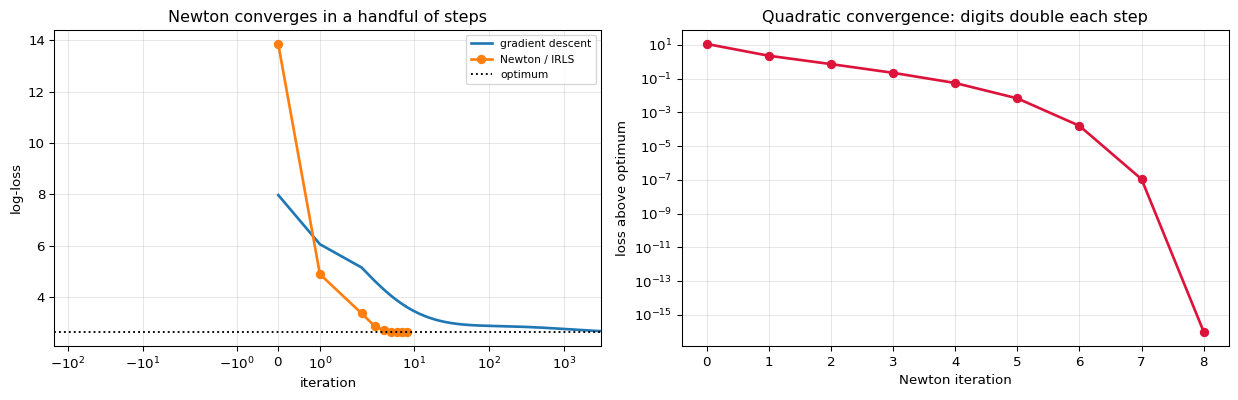

 iter      loss - optimum
--------------------------
    0           1.122e+01
    1           2.244e+00
    2           7.178e-01
    3           2.184e-01
    4           5.438e-02
    5           6.702e-03
    6           1.583e-04
    7           1.090e-07
    8           0.000e+00
--------------------------


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(hist_gd, lw=2, label="gradient descent")
axes[0].plot(np.arange(len(hist_nt)), hist_nt, "o-", lw=2, label="Newton / IRLS")
axes[0].axhline(hist_nt[-1], color="k", ls=":", lw=1.4, label="optimum")
axes[0].set(xlabel="iteration", ylabel="log-loss", xscale="symlog",
            title="Newton converges in a handful of steps")
axes[0].legend(fontsize=8); axes[0].grid(alpha=.3)

axes[1].plot(np.arange(len(hist_nt)), hist_nt - hist_nt[-1] + 1e-16, "o-", lw=2,
             color="crimson")
axes[1].set(xlabel="Newton iteration", ylabel="loss above optimum", yscale="log",
            title="Quadratic convergence: digits double each step")
axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"{'iter':>5}  {'loss - optimum':>18}")
print("-" * 26)
for k, hv in enumerate(hist_nt):
    print(f"{k:>5}  {hv - hist_nt[-1]:>18.3e}")
print("-" * 26)

---
# 5. The Decision Boundary

The boundary is where the model is undecided, $p = 0.5$, which means $z = 0$:

$$w_0 + w_1 x_1 + w_2 x_2 = 0
\qquad\Longrightarrow\qquad
x_2 = -\frac{w_0 + w_1 x_1}{w_2}$$

A **straight line** &mdash; logistic regression is a linear classifier. What the sigmoid adds
is not curvature but a graded confidence either side of that line.

boundary: +0.6608 +8.8398*spike_rate_z -2.9446*line_length_z = 0



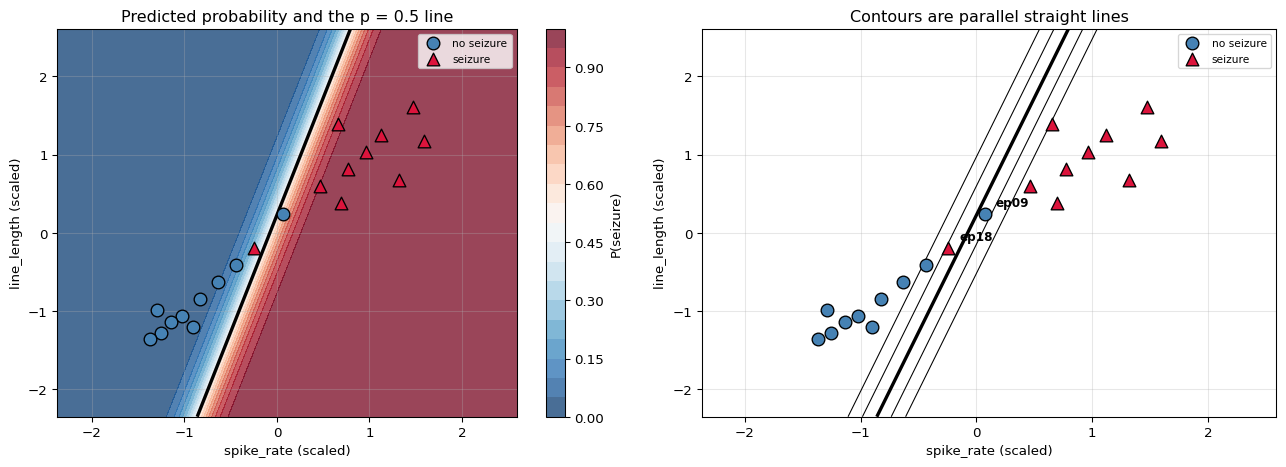

    id          p   pred   true   correct
------------------------------------------
  ep00    0.00129      0      0       yes
  ep01    0.00535      0      0       yes
  ep02    0.00057      0      0       yes
  ep03    0.01566      0      0       yes
  ep04    0.00236      0      0       yes
  ep05    0.04491      0      0       yes
  ep06    0.00039      0      0       yes
  ep07    0.02268      0      0       yes
  ep08    0.12201      0      0       yes
  ep09    0.64285      1      0        NO
  ep10    0.99386      1      1       yes
  ep11    0.99900      1      1       yes
  ep12    0.95113      1      1       yes
  ep13    0.99987      1      1       yes
  ep14    0.99791      1      1       yes
  ep15    0.91249      1      1       yes
  ep16    0.99997      1      1       yes
  ep17    0.99659      1      1       yes
  ep18    0.29113      0      1        NO
  ep19    0.99999      1      1       yes
------------------------------------------

accuracy: 0.9000  (18/20)
miscl

In [9]:
w_fit = w_nt
print(f"boundary: {w_fit[0]:+.4f} {w_fit[1]:+.4f}*{feat2[0]}_z {w_fit[2]:+.4f}*{feat2[1]}_z = 0\n")

gx, gy = np.meshgrid(np.linspace(Pz[:,0].min()-1, Pz[:,0].max()+1, 300),
                     np.linspace(Pz[:,1].min()-1, Pz[:,1].max()+1, 300))
grid = np.column_stack([np.ones(gx.size), gx.ravel(), gy.ravel()])
pp = sigmoid(grid @ w_fit).reshape(gx.shape)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))
cf = axes[0].contourf(gx, gy, pp, levels=20, cmap="RdBu_r", alpha=.75, vmin=0, vmax=1)
axes[0].contour(gx, gy, pp, levels=[.5], colors="k", linewidths=2.5)
plt.colorbar(cf, ax=axes[0], label="P(seizure)")
plot2d(ax=axes[0], scaled=True, title="Predicted probability and the p = 0.5 line")

axes[1].contour(gx, gy, pp, levels=[.1,.25,.5,.75,.9], colors="k",
                linewidths=[.8,.8,2.5,.8,.8])
plot2d(ax=axes[1], scaled=True, title="Contours are parallel straight lines")
for i in (9, 18):
    axes[1].annotate(ep_ids[i], (Pz[i,0], Pz[i,1]), fontsize=9, fontweight="bold",
                     xytext=(8, 6), textcoords="offset points")
plt.tight_layout(); plt.show()

pred = (p_fin >= .5).astype(int)
print(f"{'id':>6}  {'p':>9}  {'pred':>5}  {'true':>5}  {'correct':>8}")
print("-" * 42)
for i in range(n2):
    print(f"{ep_ids[i]:>6}  {p_fin[i]:>9.5f}  {pred[i]:>5}  {t2[i]:>5}  "
          f"{'yes' if pred[i]==t2[i] else 'NO':>8}")
print("-" * 42)
print(f"\naccuracy: {(pred==t2).mean():.4f}  "
      f"({(pred==t2).sum()}/{n2})")
wrong = np.where(pred != t2)[0]
print(f"misclassified: {[ep_ids[i] for i in wrong]}")
print(f"\nThose are the two epochs planted on the wrong side. No straight line can")
print(f"get them right - which is the honest limit of a linear classifier.")

---
# 6. Reading the Coefficients as Odds Ratios

$$\text{odds} = \frac{p}{1-p} = e^{\mathbf{x}^\top\mathbf{w}}
\qquad\Longrightarrow\qquad
\text{one unit of } x_j \text{ multiplies the odds by } e^{w_j}$$

This is the property that keeps logistic regression in clinical use: the output is not
just a prediction but a statement about how each variable changes the odds, and it holds
at every point on the curve.

In [10]:
print("coefficients on STANDARDISED features, so one unit = one std dev\n")
print(f"{'term':>14}  {'w':>10}  {'odds ratio e^w':>15}  {'reading':>34}")
print("-" * 80)
for c, v in zip(cols, w_fit):
    if c.startswith("1"):
        print(f"{c:>14}  {v:>10.5f}  {np.exp(v):>15.5f}  "
              f"{'odds at the mean of both features':>34}")
    else:
        d = "increases" if v > 0 else "decreases"
        print(f"{c:>14}  {v:>10.5f}  {np.exp(v):>15.5f}  "
              f"{'+1 sd ' + d + f' odds x{np.exp(v):.2f}':>34}")
print("-" * 80)

print(f"\nworked example, {ep_ids[0]}:")
i = 0
print(f"   standardised features: {np.round(Pz[i], 4)}")
print(f"   z = {expand(Xd[i], w_fit)}")
zi = float(Xd[i] @ w_fit)
print(f"     = {zi:+.6f}")
print(f"   odds = e^{zi:.4f} = {np.exp(zi):.6f}")
print(f"   p = odds/(1+odds) = {np.exp(zi)/(1+np.exp(zi)):.6f}")
print(f"   sigma(z)          = {float(sigmoid(zi)):.6f}   "
      f"MATCH: {np.isclose(np.exp(zi)/(1+np.exp(zi)), float(sigmoid(zi)))}")

coefficients on STANDARDISED features, so one unit = one std dev

          term           w   odds ratio e^w                             reading
--------------------------------------------------------------------------------
      1 (bias)     0.66084          1.93642   odds at the mean of both features
    spike_rate     8.83976       6903.34132       +1 sd increases odds x6903.34
   line_length    -2.94459          0.05262          +1 sd decreases odds x0.05
--------------------------------------------------------------------------------

worked example, ep00:
   standardised features: [-1.256  -1.2867]
   z = (+1.0000)*(+0.6608) + (-1.2560)*(+8.8398) + (-1.2867)*(-2.9446)
     = -6.652896
   odds = e^-6.6529 = 0.001290
   p = odds/(1+odds) = 0.001289
   sigma(z)          = 0.001289   MATCH: True


---
# 7. What Regularisation Fixes

If the classes *were* perfectly separable, the likelihood would be maximised by pushing
every $|w|$ toward infinity &mdash; the model can always make itself more certain, so no
finite optimum exists. Adding a penalty bounds it:

$$\mathcal{L}_{\text{pen}} = -\sum_i\big[y_i\log p_i + (1-y_i)\log(1-p_i)\big] + \frac{1}{2C}\lVert\mathbf{w}\rVert^2$$

scikit-learn parameterises this as $C$, the **inverse** strength: small $C$ means heavy
regularisation.

In [11]:
sep_mask = t2 == 1
Psep = Pz.copy()
Psep[sep_mask] += 3.0           # push the classes fully apart
Xsep = np.column_stack([np.ones(n2), Psep])

def fit_gd_generic(Xm, yv, eta=0.05, iters=n_it if (n_it:=4000) else 4000):
    w_ = np.zeros(Xm.shape[1])
    for _ in range(iters):
        w_ = w_ - eta * (Xm.T @ (sigmoid(Xm @ w_) - yv))
    return w_

print("what happens on PERFECTLY separable data (no penalty)\n")
print(f"{'iterations':>12}  {'||w||':>12}  {'loss':>12}")
print("-" * 40)
for it in (100, 500, 2000, 8000):
    ws = np.zeros(3)
    for _ in range(it):
        ws = ws - 0.05 * (Xsep.T @ (sigmoid(Xsep @ ws) - yb))
    ls = -np.sum(yb*np.log(sigmoid(Xsep@ws)+1e-15) + (1-yb)*np.log(1-sigmoid(Xsep@ws)+1e-15))
    print(f"{it:>12}  {np.linalg.norm(ws):>12.4f}  {ls:>12.3e}")
print("-" * 40)
print("\n||w|| keeps growing and the loss keeps falling toward zero - there is no")
print("finite optimum. The fit never converges; it only runs out of iterations.\n")

from sklearn.linear_model import LogisticRegression
print("with an L2 penalty the weights stay bounded:\n")
print(f"{'C':>10}  {'||w||':>10}  {'train acc':>10}  " +
      "  ".join(f"{f:>12}" for f in feat2))
print("-" * 62)
for Cv in (0.01, 0.1, 1.0, 10.0, 1000.0):
    m = LogisticRegression(C=Cv, l1_ratio=0, max_iter=10000).fit(Psep, t2)
    print(f"{Cv:>10.2f}  {np.linalg.norm(m.coef_):>10.4f}  {m.score(Psep, t2):>10.4f}  " +
          "  ".join(f"{v:>12.5f}" for v in m.coef_[0]))
print("-" * 62)
print("\nThat is what the penalty buys: a finite, stable answer even when the data")
print("does not constrain the direction of w at all.")

what happens on PERFECTLY separable data (no penalty)

  iterations         ||w||          loss
----------------------------------------
         100        3.2978     2.096e-01
         500        4.7129     4.429e-02
        2000        6.1124     1.221e-02
        8000        7.6226     3.331e-03
----------------------------------------

||w|| keeps growing and the loss keeps falling toward zero - there is no
finite optimum. The fit never converges; it only runs out of iterations.

with an L2 penalty the weights stay bounded:

         C       ||w||   train acc    spike_rate   line_length
--------------------------------------------------------------
      0.01      0.2158      1.0000       0.15286       0.15226
      0.10      0.6553      1.0000       0.46503       0.46169
      1.00      1.2278      1.0000       0.87470       0.86156
     10.00      1.9220      1.0000       1.37353       1.34448
   1000.00      3.7260      1.0000       2.95433       2.27040
-----------------------

---
# 8. Checking Against scikit-learn

`LogisticRegression(C=np.inf)` optimises exactly the unpenalised loss derived above,
so the coefficients should agree with the hand-run Newton iteration.

In [12]:
sk = LogisticRegression(C=np.inf, max_iter=10000, tol=1e-12).fit(Pz, t2)
sk_w = np.r_[sk.intercept_, sk.coef_[0]]

print(f"{'term':>14}  {'ours (Newton)':>15}  {'sklearn':>13}  {'diff':>11}")
print("-" * 60)
for c, a, b in zip(cols, w_fit, sk_w):
    print(f"{c:>14}  {a:>15.8f}  {b:>13.8f}  {abs(a-b):>11.2e}")
print("-" * 60)
print(f"\ncoefficients MATCH : {np.allclose(w_fit, sk_w, atol=1e-5)}")
print(f"probabilities MATCH: {np.allclose(p_fin, sk.predict_proba(Pz)[:,1], atol=1e-6)}")
print(f"predictions MATCH  : {np.array_equal(pred, sk.predict(Pz))}")

from sklearn.metrics import log_loss as sk_ll
print(f"\nlog-loss ours    : {hist_nt[-1]/n2:.10f}  (per sample)")
print(f"log-loss sklearn : {sk_ll(t2, sk.predict_proba(Pz)):.10f}")
print(f"MATCH: {np.isclose(hist_nt[-1]/n2, sk_ll(t2, sk.predict_proba(Pz)), atol=1e-8)}")

print(f"\ngradient descent vs Newton (both ours):")
print(f"   ||w_gd - w_newton|| = {np.linalg.norm(w_gd - w_nt):.6e}")
print(f"   same solution? {np.allclose(w_gd, w_nt, atol=1e-3)}")

          term    ours (Newton)        sklearn         diff
------------------------------------------------------------
      1 (bias)       0.66083921     0.66083967     4.62e-07
    spike_rate       8.83976082     8.83976425     3.43e-06
   line_length      -2.94459034    -2.94459240     2.07e-06
------------------------------------------------------------

coefficients MATCH : True
probabilities MATCH: True
predictions MATCH  : True

log-loss ours    : 0.1321443769  (per sample)
log-loss sklearn : 0.1321443769
MATCH: True

gradient descent vs Newton (both ours):
   ||w_gd - w_newton|| = 3.028482e+00
   same solution? False


---
# 9. Summary

| Stage | Formula | Note |
|---|---|---|
| Linear part | $z = \mathbf{x}^\top\mathbf{w}$ | identical to linear regression |
| Link | $p = \sigma(z) = 1/(1+e^{-z})$ | maps $\mathbb{R} \to (0,1)$ |
| Loss | $-\sum y\log p + (1-y)\log(1-p)$ | convex, unbounded when wrong |
| Gradient | $X^\top(\mathbf{p}-\mathbf{y})$ | the $p(1-p)$ cancels |
| Hessian | $X^\top S X$, $S = \mathrm{diag}(p(1-p))$ | down-weights confident points |
| Boundary | $\mathbf{x}^\top\mathbf{w} = 0$ | a straight line |
| Coefficient | $e^{w_j}$ | odds ratio |

**The one idea:** the sigmoid and log-loss are chosen *together*. Either alone is
awkward; paired, the derivative collapses to $p - y$ and the problem stays convex.

**Its honest limit:** the boundary is linear. The two planted epochs are misclassified
and no amount of fitting will fix that &mdash; it needs a non-linear model, which is what the
SVM-with-kernel and neural-network walkthroughs provide.

**What is deliberately left out:** multinomial/softmax regression, L1-penalised logistic
regression, class weights for imbalanced data, calibration, ROC/AUC analysis, and the
statistical machinery (Wald tests, deviance, confidence intervals on odds ratios).